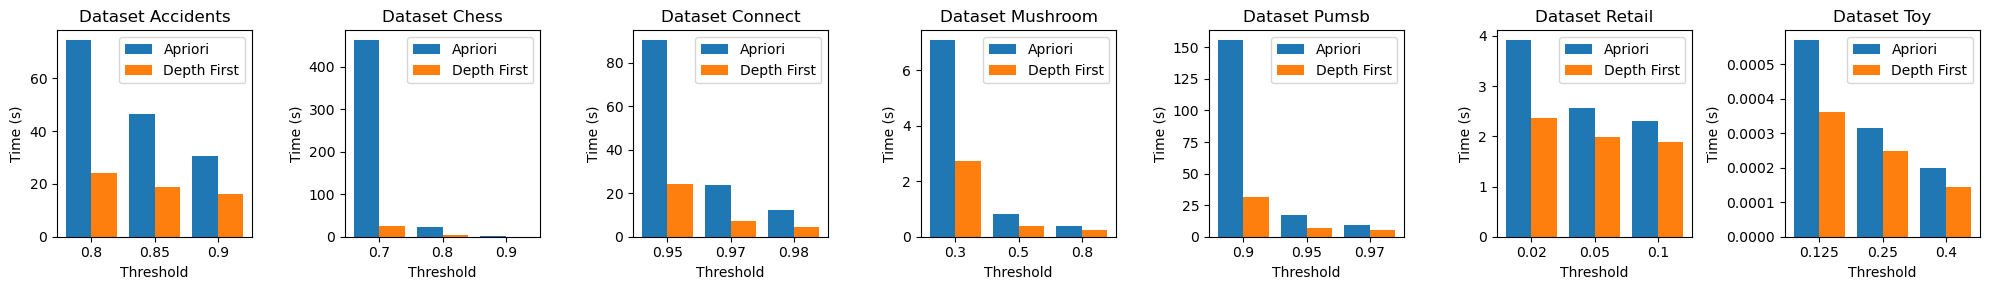

In [7]:
import pandas as pd
import matplotlib.pyplot as plt
import numpy as np

# Charger les données
df = pd.read_csv('execution_times.csv')

# Grouper par test
grouped = list(df.groupby('Test'))
num_tests = len(grouped)

# Créer la figure avec subplots
fig, axes = plt.subplots(1, 7, figsize=(20, 3))  # 3 lignes, 3 colonnes
axes = axes.flatten()  # Transformer en liste pour un accès facile

# Boucle sur chaque test pour remplir les subplots
for i, (name, group) in enumerate(grouped):
    x = np.arange(len(group))  # Positions des barres sur l'axe x
    width = 0.4  # Largeur des barres

    axes[i].bar(x - width/2, group['Apriori Time (s)'], width, label='Apriori')
    axes[i].bar(x + width/2, group['Alternative Miner Time (s)'], width, label='Depth First')

    # Ajouter les labels et le titre
    axes[i].set_xticks(x)
    axes[i].set_xticklabels(group['Threshold'])
    axes[i].set_xlabel('Threshold')
    axes[i].set_ylabel('Time (s)')
    axes[i].set_title(name)
    axes[i].legend()

# Supprimer les subplots vides (si on a moins de 9 tests)
for j in range(num_tests, 7):
    fig.delaxes(axes[j])

# Ajuster la mise en page
plt.tight_layout()
plt.show()

Test,Threshold,Apriori Time (s),Apriori Memory (KB),Alternative Miner Time (s),Alternative Miner Memory (KB)
Datasets/accidents/accidents.dat,0.8,74.50972167080036,885352.0740234375,24.204575362398465,1018138.4302734375
Datasets/accidents/accidents.dat,0.85,46.6755728540993,885316.7966796875,18.75864106230074,911631.4716796875
Datasets/accidents/accidents.dat,0.9,30.692489549997845,885300.1940429688,16.01324389990041,801034.8544921875
Datasets/chess/chess.dat,0.7,463.0426811206991,23244.5755859375,26.254356646000087,72005.6404296875
Datasets/chess/chess.dat,0.8,22.542854012400493,10956.65654296875,3.989830075098871,25157.61123046875
Datasets/chess/chess.dat,0.9,1.1847469789994647,8479.27685546875,0.36239290830053505,14522.55751953125
Datasets/connect/connect.dat,0.95,90.38548361679932,182325.9591796875,24.109748912501527,313075.6815429687
Datasets/connect/connect.dat,0.97,23.93309573749939,181791.0958984375,7.06907594999866,248784.29404296874
Datasets/connect/connect.dat,0.98,12.180552337398694,181687.7154296875,4.650919520799652,232263.2083984375
Datasets/mushroom/mushroom.dat,0.3,7.078162083400093,20971.7107421875,2.7201585709983194,33435.3169921875
Datasets/mushroom/mushroom.dat,0.5,0.8285993040008179,20122.75185546875,0.396926070900372,23358.0021484375
Datasets/mushroom/mushroom.dat,0.8,0.3823049582002568,20083.2279296875,0.23286937509983546,16907.4552734375
Datasets/pumsb/pumsb.dat,0.9,155.6589863166999,217552.6498046875,31.285202037497946,487907.6396484375
Datasets/pumsb/pumsb.dat,0.95,17.429327029098204,216610.9169921875,6.541256362601416,381347.4671875
Datasets/pumsb/pumsb.dat,0.97,9.088384695900459,216548.5474609375,5.712942625000869,344458.2890625
Datasets/retail/retail.dat,0.02,3.9156529581989163,106216.6060546875,2.3666735877013707,96296.75107421874
Datasets/retail/retail.dat,0.05,2.565281837499788,106181.7404296875,1.9823175206998713,95582.1107421875
Datasets/retail/retail.dat,0.1,2.30902194179871,106179.2802734375,1.8858358959005272,94554.7615234375
Datasets/toy/toy.dat,0.125,0.0005691499005479273,14.00625,0.0003601458010962233,16.2623046875
Datasets/toy/toy.dat,0.25,0.00031552500076941213,13.9796875,0.0002491749000910204,13.9796875
Datasets/toy/toy.dat,0.4,0.0001975999999558553,13.9609375,0.00014255849964683875,13.9609375

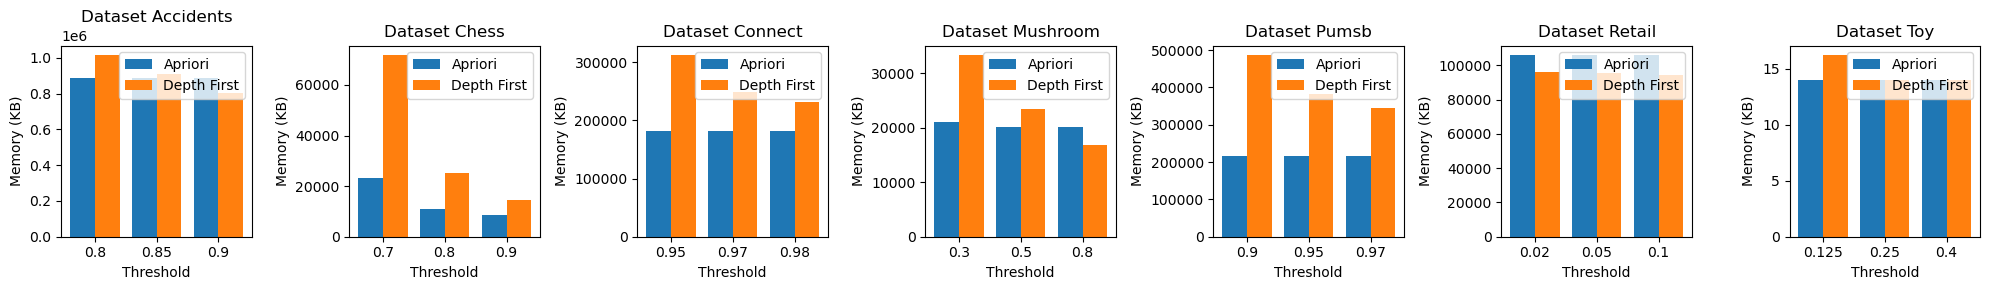

In [ ]:
# Créer la figure avec subplots
fig, axes = plt.subplots(1, 7, figsize=(20, 3))  # 2 lignes, 4 colonnes
axes = axes.flatten()  # Transformer en liste pour un accès facile

# Boucle sur chaque test pour remplir les subplots
for i, (name, group) in enumerate(grouped):
    x = np.arange(len(group))  # Positions des barres sur l'axe x
    width = 0.4  # Largeur des barres

    axes[i].bar(x - width/2, group['Apriori Memory (KB)'], width, label='Apriori')
    axes[i].bar(x + width/2, group['Alternative Miner Memory (KB)'], width, label='Depth First')

    # Ajouter les labels et le titre
    axes[i].set_xticks(x)
    axes[i].set_xticklabels(group['Threshold'])
    axes[i].set_xlabel('Threshold')
    axes[i].set_ylabel('Memory (KB)')
    axes[i].set_title(name)
    axes[i].legend()

# Supprimer les subplots vides (si on a moins de 8 tests)
for j in range(num_tests, 7):
    fig.delaxes(axes[j])

# Ajuster la mise en page
plt.tight_layout()
plt.show()

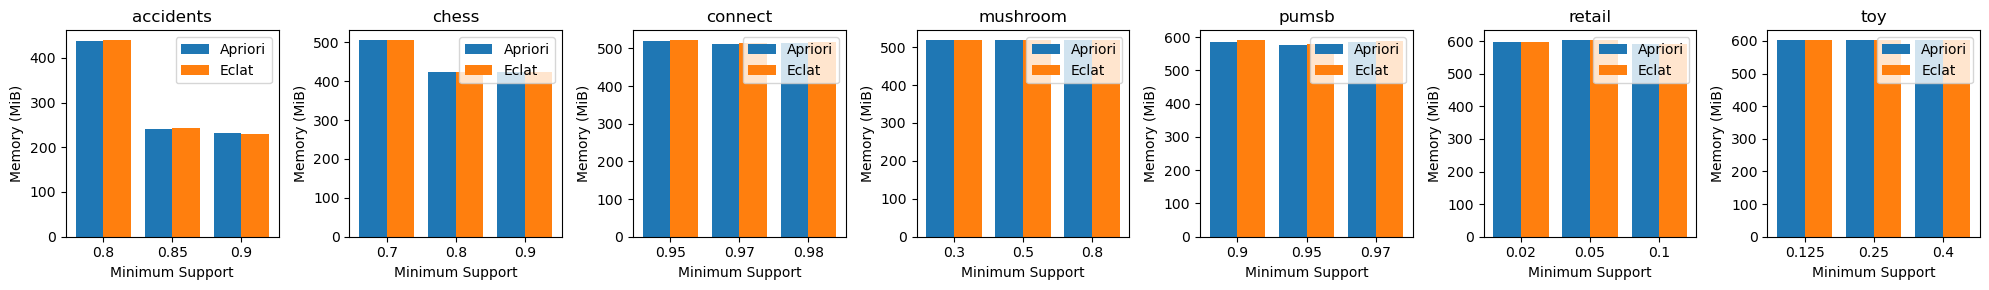

In [13]:
import pandas as pd
import matplotlib.pyplot as plt
import numpy as np

df = pd.read_csv('Data copy.csv')

# delete the first column
df = df.drop(df.columns[0], axis=1)


# do the mean  of the Memory_1(Mib) for each Algo, dataset and men_value
df = df.groupby(['Algo', 'dataset', 'min_value'])['Memory_1 (Mib)'].mean().reset_index()

# Group data by dataset
grouped_datasets = list(df.groupby('dataset'))
num_datasets = len(grouped_datasets)

# Create figure with subplots
fig, axes = plt.subplots(1, num_datasets, figsize=(20, 3))
axes = axes.flatten()  # Transform to list for easy access

# Loop through each dataset to fill the subplots
for i, (name, group) in enumerate(grouped_datasets):
    # Get data for each algorithm
    pivot_data = group.pivot(index='min_value', columns='Algo', values='Memory_1 (Mib)').reset_index()
    
    x = np.arange(len(pivot_data))  # Bar positions on x-axis
    width = 0.4  # Bar width
    
    axes[i].bar(x - width/2, pivot_data['Apriori'], width, label='Apriori')
    axes[i].bar(x + width/2, pivot_data['Eclat'], width, label='Eclat')
    
    # Add labels and title
    axes[i].set_xticks(x)
    axes[i].set_xticklabels(pivot_data['min_value'])
    axes[i].set_xlabel('Minimum Support')
    axes[i].set_ylabel('Memory (MiB)')
    axes[i].set_title(name)
    axes[i].legend()

# Adjust layout
plt.tight_layout()
plt.show()
